In [16]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

#### **Generate Data**

In [17]:
X_train = np.linspace(-1, 1, 20)
X_train

array([-1.        , -0.89473684, -0.78947368, -0.68421053, -0.57894737,
       -0.47368421, -0.36842105, -0.26315789, -0.15789474, -0.05263158,
        0.05263158,  0.15789474,  0.26315789,  0.36842105,  0.47368421,
        0.57894737,  0.68421053,  0.78947368,  0.89473684,  1.        ])

In [18]:
y_train = np.array(
    [
        -0.6561, -0.3099, -0.59035, -0.50855, 
        -0.285, -0.2443, -0.02445, 0.00135, 
        -0.2006, 0.07475, -0.1422, 0.06515, 
        0.15265, 0.3521, 0.28415, 0.5524, 
        0.23115, 0.20835, 0.4211, 0.60485
    ]
)
y_train

array([-0.6561 , -0.3099 , -0.59035, -0.50855, -0.285  , -0.2443 ,
       -0.02445,  0.00135, -0.2006 ,  0.07475, -0.1422 ,  0.06515,
        0.15265,  0.3521 ,  0.28415,  0.5524 ,  0.23115,  0.20835,
        0.4211 ,  0.60485])

In [19]:
X_test = np.linspace(-1, 1, 20)
X_test

array([-1.        , -0.89473684, -0.78947368, -0.68421053, -0.57894737,
       -0.47368421, -0.36842105, -0.26315789, -0.15789474, -0.05263158,
        0.05263158,  0.15789474,  0.26315789,  0.36842105,  0.47368421,
        0.57894737,  0.68421053,  0.78947368,  0.89473684,  1.        ])

In [20]:
y_test = np.array(
    [
        -0.69415, -0.451, -0.43005, -0.4484,
        -0.1475, -0.5019, -0.28055, 0.24595,
        -0.21425, -0.0286, 0.23415, 0.46575,
        0.07955, 0.1973, 0.0719, 0.3639, 
        0.5536, 0.3365, 0.50705, 0.33435
    ]
)
y_test

array([-0.69415, -0.451  , -0.43005, -0.4484 , -0.1475 , -0.5019 ,
       -0.28055,  0.24595, -0.21425, -0.0286 ,  0.23415,  0.46575,
        0.07955,  0.1973 ,  0.0719 ,  0.3639 ,  0.5536 ,  0.3365 ,
        0.50705,  0.33435])

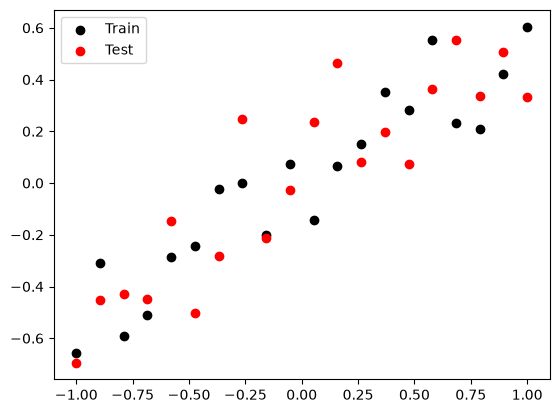

In [21]:
plt.scatter(X_train, y_train, c = 'black', label = 'Train')
plt.scatter(X_test, y_test, c = 'red', label = 'Test')
plt.legend()
plt.show()

#### **Regression Model**

In [22]:
model = Sequential()

model.add(Dense(128, input_dim = 1, activation = 'relu'))
model.add(Dense(128, activation = 'relu'))
model.add(Dense(1, activation = 'linear'))

adam = Adam(learning_rate = 0.01)
model.compile(
    loss = 'mse',
    optimizer = adam,
    metrics = ['mse']
)

history = model.fit(
    X_train,
    y_train,
    epochs = 500,
    validation_data = (X_test, y_test),
    verbose = 1
)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - loss: 0.1207 - mse: 0.1207 - val_loss: 0.0315 - val_mse: 0.0315
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0195 - mse: 0.0195 - val_loss: 0.0528 - val_mse: 0.0528
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0408 - mse: 0.0408 - val_loss: 0.0396 - val_mse: 0.0396
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0269 - mse: 0.0269 - val_loss: 0.0320 - val_mse: 0.0320
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0187 - mse: 0.0187 - val_loss: 0.0393 - val_mse: 0.0393
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0256 - mse: 0.0256 - val_loss: 0.0396 - val_mse: 0.0396
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0256 - mse: 0.0256 - val_loss: 0.0346 - val_mse: 0.0346
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0207 - mse: 0.0207 - val_loss: 0.0316 - val_mse: 0.0316
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0179 - mse:

### **Evaluate the model**

In [23]:
_, train_mse = model.evaluate(X_train, y_train, verbose = 1)
_, test_mse = model.evaluate(X_test, y_test, verbose = 1)

print(f'Train loss: {train_mse}, Test loss: {test_mse}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0099 - mse: 0.0099
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0381 - mse: 0.0381
Train loss: 0.009925337508320808, Test loss: 0.03807178884744644


In [24]:
y_predict = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


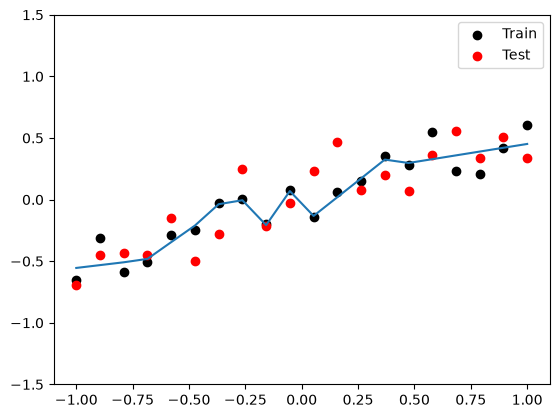

In [25]:
plt.figure()
plt.scatter(X_train, y_train, c = 'black', label = 'Train')
plt.scatter(X_test, y_test, c = 'red', label = 'Test')
plt.plot(X_test, y_predict)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.show()

Look carefully you can see the curver prioritize the black point rather red

+ this tell there some overfitting occured

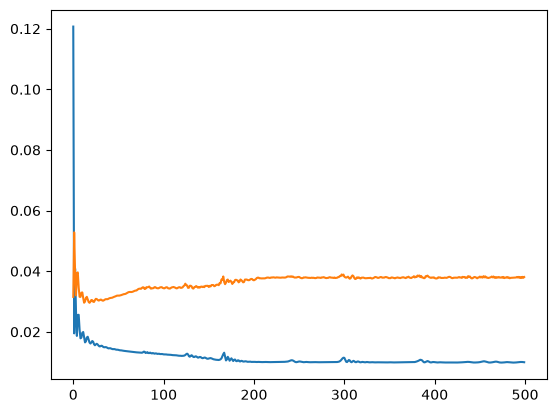

In [26]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.show()

Training and testin loss larger again it tells there is some overfitting

### **Dropout Model**

In [37]:
model = Sequential()

model.add(Dense(128, input_dim = 1, activation = 'relu'))
model.add(Dropout(0.2)) # 20% node turn-off

model.add(Dense(128, activation = 'relu'))
model.add(Dropout(0.2)) # 20% node turn-off

model.add(Dense(1, activation = 'linear'))
adam = Adam(learning_rate = 0.01)

model.compile(
    loss = 'mse',
    optimizer = adam,
    metrics = ['mse']
)

history = model.fit(
    X_train,
    y_train,
    epochs = 500,
    validation_data = (X_test, y_test),
    verbose = 1
)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - loss: 0.1110 - mse: 0.1110 - val_loss: 0.0282 - val_mse: 0.0282
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0227 - mse: 0.0227 - val_loss: 0.0563 - val_mse: 0.0563
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0518 - mse: 0.0518 - val_loss: 0.0363 - val_mse: 0.0363
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0270 - mse: 0.0270 - val_loss: 0.0308 - val_mse: 0.0308
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0151 - mse: 0.0151 - val_loss: 0.0430 - val_mse: 0.0430
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0296 - mse: 0.0296 - val_loss: 0.0405 - val_mse: 0.0405
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0316 - mse: 0.0316 - val_loss: 0.0320 - val_mse: 0.0320
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0228 - mse: 0.0228 - val_loss: 0.0282 - val_mse: 0.0282
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0159 - mse:

In [38]:
_, train_mse = model.evaluate(X_train, y_train, verbose = 1)
_, test_mse = model.evaluate(X_test, y_test, verbose = 1)

print(f'Train loss: {train_mse}, Test loss: {test_mse}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0118 - mse: 0.0118
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0393 - mse: 0.0393
Train loss: 0.01177414320409298, Test loss: 0.03929572179913521


In [39]:
y_predict = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


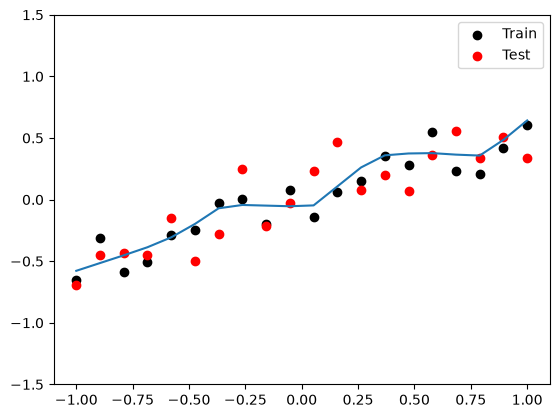

In [40]:
plt.figure()
plt.scatter(X_train, y_train, c = 'black', label = 'Train')
plt.scatter(X_test, y_test, c = 'red', label = 'Test')
plt.plot(X_test, y_predict)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.show()

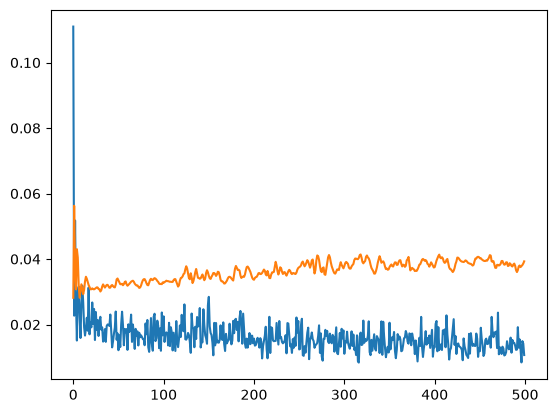

In [41]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.show()

### **Dropout Model for 50%**

In [42]:
model = Sequential()

model.add(Dense(128, input_dim = 1, activation = 'relu'))
model.add(Dropout(0.5)) # 20% node turn-off

model.add(Dense(128, activation = 'relu'))
model.add(Dropout(0.5)) # 20% node turn-off

model.add(Dense(1, activation = 'linear'))
adam = Adam(learning_rate = 0.01)

model.compile(
    loss = 'mse',
    optimizer = adam,
    metrics = ['mse']
)

history = model.fit(
    X_train,
    y_train,
    epochs = 500,
    validation_data = (X_test, y_test),
    verbose = 1
)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - loss: 0.1406 - mse: 0.1406 - val_loss: 0.0387 - val_mse: 0.0387
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0460 - mse: 0.0460 - val_loss: 0.0449 - val_mse: 0.0449
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0348 - mse: 0.0348 - val_loss: 0.0569 - val_mse: 0.0569
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0649 - mse: 0.0649 - val_loss: 0.0382 - val_mse: 0.0382
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0414 - mse: 0.0414 - val_loss: 0.0300 - val_mse: 0.0300
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0204 - mse: 0.0204 - val_loss: 0.0388 - val_mse: 0.0388
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0420 - mse: 0.0420 - val_loss: 0.0455 - val_mse: 0.0455
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0337 - mse: 0.0337 - val_loss: 0.0422 - val_mse: 0.0422
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0470 - mse:

In [43]:
_, train_mse = model.evaluate(X_train, y_train, verbose = 1)
_, test_mse = model.evaluate(X_test, y_test, verbose = 1)

print(f'Train loss: {train_mse}, Test loss: {test_mse}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0136 - mse: 0.0136
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0332 - mse: 0.0332
Train loss: 0.013593274168670177, Test loss: 0.03316420316696167


In [44]:
y_predict = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


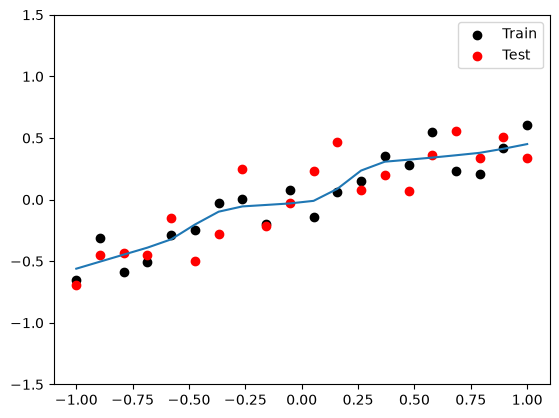

In [45]:
plt.figure()
plt.scatter(X_train, y_train, c = 'black', label = 'Train')
plt.scatter(X_test, y_test, c = 'red', label = 'Test')
plt.plot(X_test, y_predict)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.show()

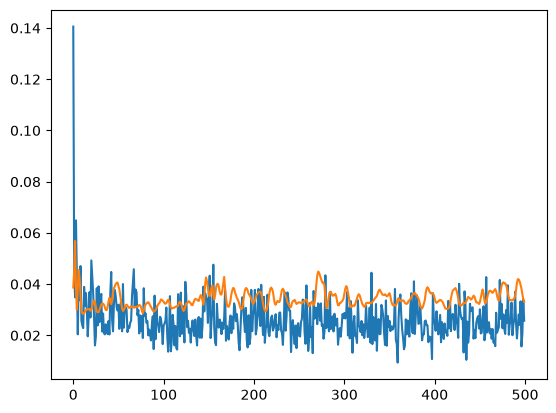

In [46]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.show()